In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Skincare-Enriched-Final.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

Dataset shape: (1466, 10)

Column names:
['product_name', 'mrp', 'selling_price', 'discount', 'rating', 'review_count', 'brand_name', 'brand_origin_country', 'brand_origin_group', 'category']

Data types:
product_name                str
mrp                       int64
selling_price           float64
discount                    str
rating                  float64
review_count            float64
brand_name                  str
brand_origin_country        str
brand_origin_group          str
category                    str
dtype: object

First five records:


,product_name,mrp,selling_price,discount,rating,review_count,brand_name,brand_origin_country,brand_origin_group,category
0,CeraVe Foaming Cleanser Face Wash For Oily Ski...,559,503.0,10% Off,4.0,30024.0,CeraVe,United States,International,Cleanser / Face Wash
1,The Derma Co 10% Niacinamide Face Serum For Ac...,849,594.0,30% Off,4.0,75417.0,The Derma Co,India,Indian,Serum
2,Dot & Key Vitamin C + E Super Bright Sunscreen...,445,387.0,13% Off,4.0,174017.0,Dot & Key,India,Indian,Sunscreen
3,"Anua Niacinamide 10 Txa 4 Serum, Brightening K...",2000,1900.0,5% Off,4.0,3266.0,Anua,South Korea,International,Serum
4,Eucerin Anti Pigment Cleansing Gel 2% Exfoliat...,1100,1045.0,5% Off,4.0,448.0,Eucerin,Germany,International,Exfoliator / Scrub


In [2]:
# Summary of numerical variables
display(df.describe().round(2))

# Distribution of categorical variables
print("Product categories:")
display(df["category"].value_counts().to_frame("product_count"))

print("Brand origin groups:")
display(df["brand_origin_group"].value_counts().to_frame("product_count"))

,mrp,selling_price,rating,review_count
count,1466.00,1466.00,1466.00,1466.00
mean,934.38,785.67,4.18,37427.26
std,1030.43,891.05,0.39,354977.16
min,49.00,39.00,3.00,1.00
25%,395.00,319.00,4.00,578.25
50%,599.00,496.50,4.00,1969.50
75%,1045.25,899.00,4.00,9533.50
max,12000.00,10800.00,5.00,7997482.00


Product categories:


,product_count
category,
Moisturizer,258
Sunscreen,223
Cleanser / Face Wash,189
Other / Unclear,175
Serum,173
Lip Care,101
Face Mask,84
Body Care,71
Toner,63


Brand origin groups:


,product_count
brand_origin_group,
Indian,1016
International,449
Unknown,1


In [3]:
# Convert the displayed discount text into a numeric percentage
df["discount_pct_reported"] = (
    df["discount"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
    .astype(float)
)

# Calculate discount percentage directly from MRP and selling price
df["discount_pct"] = (
    (df["mrp"] - df["selling_price"]) / df["mrp"]
) * 100

# Calculate absolute savings
df["savings"] = df["mrp"] - df["selling_price"]

# Create log-transformed review counts for later analysis
df["log_review_count"] = np.log1p(df["review_count"])

display(
    df[[
        "mrp", "selling_price", "discount",
        "discount_pct_reported", "discount_pct",
        "savings", "review_count", "log_review_count"
    ]].head(10).round(2)
)

,mrp,selling_price,discount,discount_pct_reported,discount_pct,savings,review_count,log_review_count
0,559,503.0,10% Off,10.0,10.02,56.0,30024.0,10.31
1,849,594.0,30% Off,30.0,30.04,255.0,75417.0,11.23
2,445,387.0,13% Off,13.0,13.03,58.0,174017.0,12.07
3,2000,1900.0,5% Off,5.0,5.00,100.0,3266.0,8.09
4,1100,1045.0,5% Off,5.0,5.00,55.0,448.0,6.11
5,549,467.0,15% Off,15.0,14.94,82.0,15342.0,9.64
6,459,418.0,9% Off,9.0,8.93,41.0,437378.0,12.99
7,545,480.0,12% Off,12.0,11.93,65.0,23412.0,10.06
8,3780,3213.0,15% Off,15.0,15.00,567.0,1781.0,7.49
9,249,237.0,5% Off,5.0,4.82,12.0,21683.0,9.98


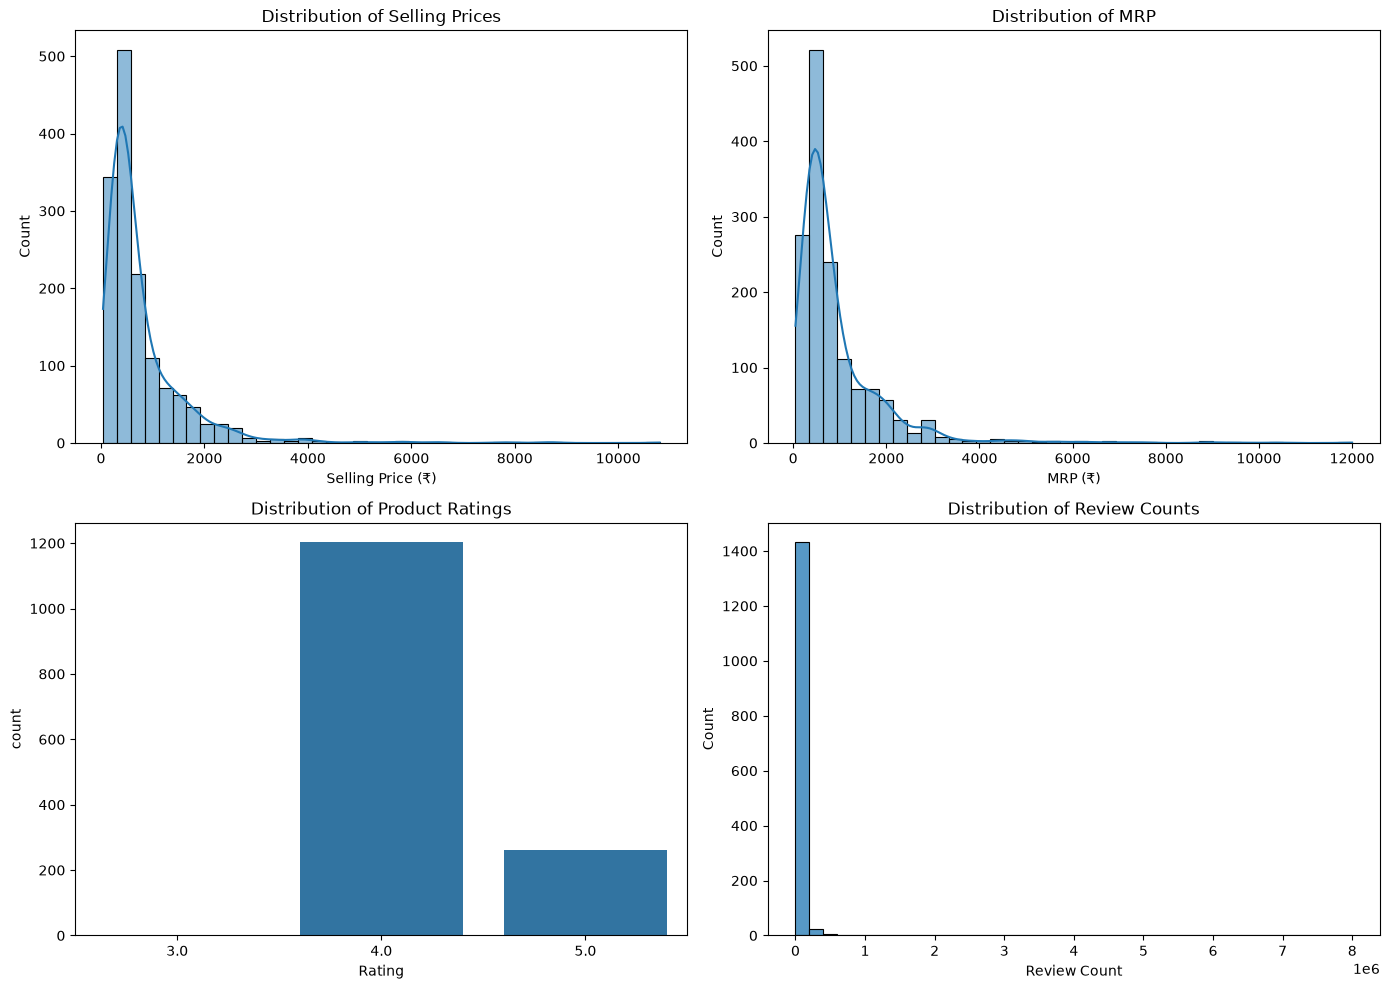

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Selling price distribution
sns.histplot(
    data=df,
    x="selling_price",
    bins=40,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Selling Prices")
axes[0, 0].set_xlabel("Selling Price (₹)")

# 2. MRP distribution
sns.histplot(
    data=df,
    x="mrp",
    bins=40,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of MRP")
axes[0, 1].set_xlabel("MRP (₹)")

# 3. Rating distribution
sns.countplot(
    data=df,
    x="rating",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Product Ratings")
axes[1, 0].set_xlabel("Rating")

# 4. Review count distribution
sns.histplot(
    data=df,
    x="review_count",
    bins=40,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Distribution of Review Counts")
axes[1, 1].set_xlabel("Review Count")

plt.tight_layout()
plt.show()

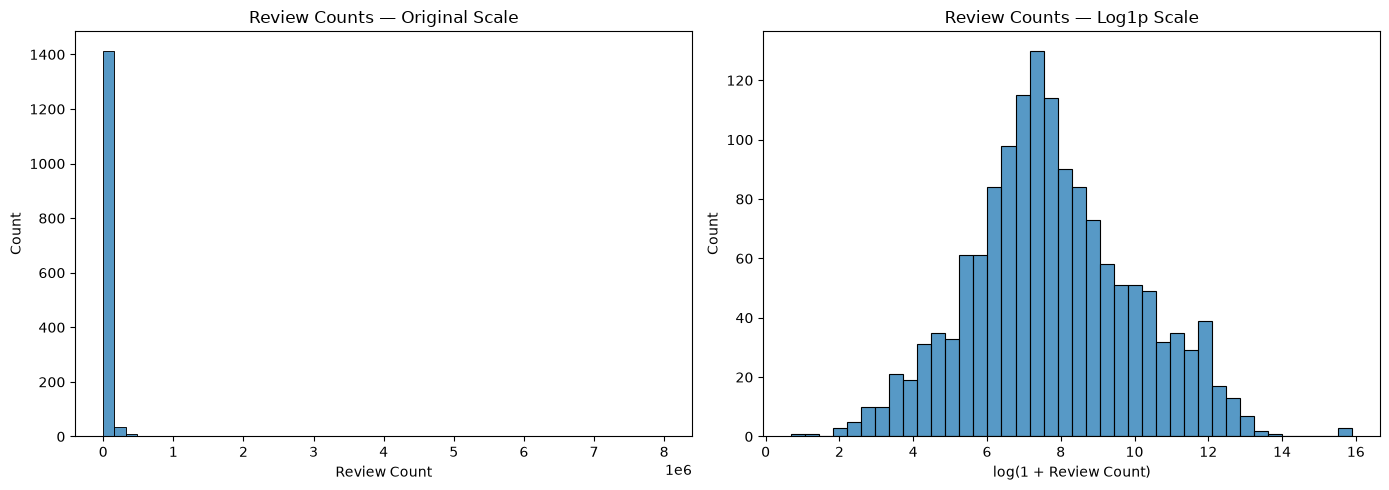

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original scale
sns.histplot(data=df, x="review_count", bins=50, ax=axes[0])
axes[0].set_title("Review Counts — Original Scale")
axes[0].set_xlabel("Review Count")

# Log-transformed scale
sns.histplot(data=df, x="log_review_count", bins=40, ax=axes[1])
axes[1].set_title("Review Counts — Log1p Scale")
axes[1].set_xlabel("log(1 + Review Count)")

plt.tight_layout()
plt.show()

In [6]:
Q1 = df["selling_price"].quantile(0.25)
Q3 = df["selling_price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["selling_price"] < lower_bound) |
    (df["selling_price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of price outliers:", len(outliers))
print("Percentage of dataset:", round(len(outliers) / len(df) * 100, 2), "%")

display(
    outliers[
        ["product_name", "mrp", "selling_price", "rating", "review_count"]
    ].sort_values("selling_price", ascending=False).head(15)
)

Q1: 319.0
Q3: 899.0
IQR: 580.0
Lower bound: -551.0
Upper bound: 1769.0
Number of price outliers: 131
Percentage of dataset: 8.94 %


,product_name,mrp,selling_price,rating,review_count
1351,Charlotte Tilbury Magic Water Cream,12000,10800.0,4.0,68.0
1122,Estee Lauder P.M Routine Kit (Advanced Night R...,10300,8755.0,4.0,55167.0
1441,Charlotte Tilbury Collagen Superfusion Face Oil,9550,8595.0,4.0,131.0
404,Charlotte Tilbury Charlotte's Magic Serum Crys...,8850,7965.0,4.0,1363.0
397,Estee Lauder Advanced Night Repair Serum Duo,9000,7650.0,4.0,13073.0
230,Charlotte Tilbury Magic Cream,7300,6570.0,5.0,42.0
1220,Charlotte Tilbury's Legendary Minis - Medium,7600,6460.0,5.0,19129.0
1232,ISDIN K-ox Eyes Cream,6300,5985.0,4.0,65.0
764,Kiehl's Super Multi-Corrective Cream with Prox...,6900,5865.0,4.0,217.0
901,d'you Ultimate Skin Treat And Repair Duo,6700,5695.0,4.0,4491.0


In [7]:
display(
    df.nlargest(10, "review_count")[
        ["product_name", "brand_name", "category", "review_count"]
    ]
)

,product_name,brand_name,category,review_count
442,Nykaa Naturals Skin Secrets Bestseller Sheet M...,Nykaa,Face Mask,7997482.0
15,Nykaa Green Tea + Aloe Vera Sheet Mask For Hyd...,Nykaa,Face Mask,7619790.0
250,Nykaa Gold Sheet Mask For Revitalized & Youthf...,Nykaa,Face Mask,7619790.0
212,"Nykaa Anti-Acne Face Wash With Salicylic Acid,...",Nykaa,Cleanser / Face Wash,882318.0
42,Ponds Super Light Gel Oil-Free Moisturize with...,Pond's,Moisturizer,678887.0
117,Nykaa Wanderlust Hand & Nail Cream - Rose & Wh...,Nykaa,Moisturizer,653754.0
190,Minimalist Daily Skincare Routine For Oily & A...,Minimalist,Facial Oil,524663.0
752,Neutrogena Ultrasheer SPF50+ PA++++ Moisturizi...,Neutrogena,Sunscreen,483366.0
1164,Nykaa Naturals Glow Boosting Serum Oil with Na...,Nykaa,Serum,467643.0
6,"Cetaphil Gentle Skin Cleanser For Normal, Dry ...",Cetaphil,Cleanser / Face Wash,437378.0


In [8]:
print("Maximum review count:", df["review_count"].max())

print(
    "Products with over 1 million reviews:",
    (df["review_count"] > 1_000_000).sum()
)

Maximum review count: 7997482.0
Products with over 1 million reviews: 3


In [9]:
extreme_reviews = df[df["review_count"] > 1_000_000][
    ["product_name", "brand_name", "category", "review_count"]
].copy()

display(extreme_reviews.to_string(index=False))

'                                                   product_name brand_name  category  review_count\nNykaa Green Tea + Aloe Vera Sheet Mask For Hydrated Skin - F...      Nykaa Face Mask     7619790.0\nNykaa Gold Sheet Mask For Revitalized & Youthful Skin-Formul...      Nykaa Face Mask     7619790.0\nNykaa Naturals Skin Secrets Bestseller Sheet Mask - Monthly ...      Nykaa Face Mask     7997482.0'

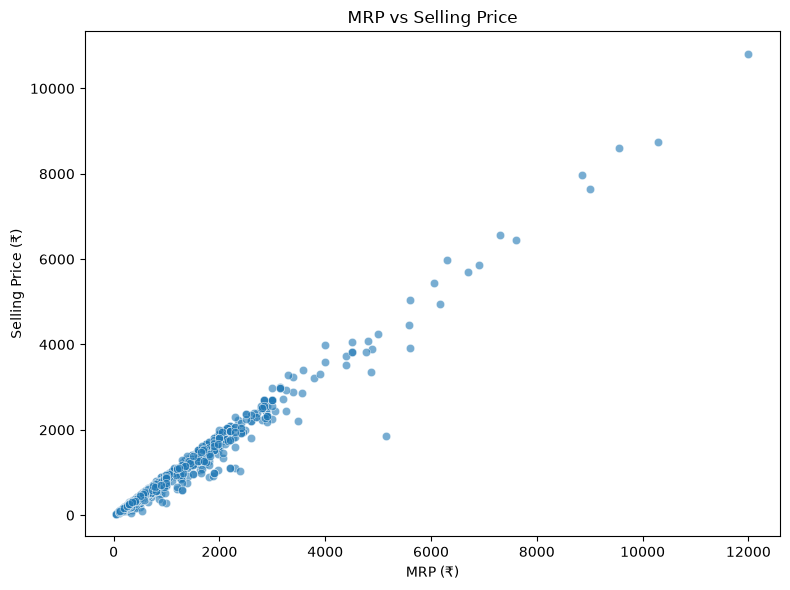

Pearson correlation: 0.988


,product_name,mrp,selling_price,savings
1035,Sulwhasoo Ginseng Peptide Ritual,5140,1850.0,3290.0
1165,Aroma Magic Vitamin C Skin Brightening Facial Kit,5600,3920.0,1680.0
1122,Estee Lauder P.M Routine Kit (Advanced Night R...,10300,8755.0,1545.0
1297,Neutrogena Visible Repair Complete Care Combo,4859,3360.0,1499.0
1402,Olay Vitamin C Kit - Super Serum With Free Cle...,2398,1031.0,1367.0
397,Estee Lauder Advanced Night Repair Serum Duo,9000,7650.0,1350.0
434,Winston 3 In 1 LED Light Therapy Face Mask for...,3490,2199.0,1291.0
1260,Eucerin Anti-Pigment Dual Serum & Dark Circle ...,6174,4939.0,1235.0
602,Bath & Body Works A Thousand Wishes Ultimate H...,2299,1099.0,1200.0
1351,Charlotte Tilbury Magic Water Cream,12000,10800.0,1200.0


In [10]:
# Relationship between MRP and selling price
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="mrp",
    y="selling_price",
    alpha=0.6
)

plt.title("MRP vs Selling Price")
plt.xlabel("MRP (₹)")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

# Calculate correlation
print(
    "Pearson correlation:",
    round(df["mrp"].corr(df["selling_price"]), 3)
)

# Products with the largest absolute savings
df["savings"] = df["mrp"] - df["selling_price"]

display(
    df.nlargest(10, "savings")[
        ["product_name", "mrp", "selling_price", "savings"]
    ]
)

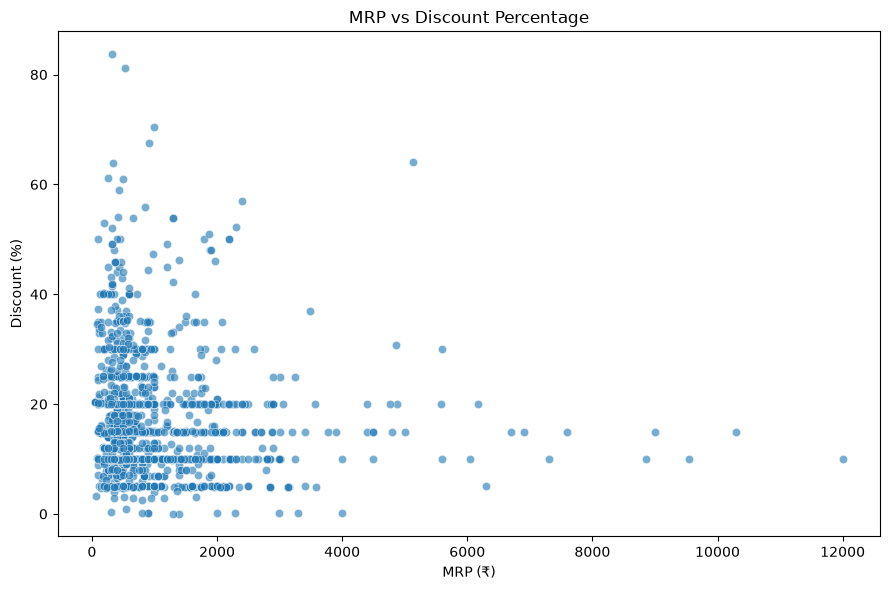

Pearson correlation: -0.051
Spearman correlation: -0.074


In [11]:
# Calculate discount percentage from prices
df["discount_pct"] = (
    (df["mrp"] - df["selling_price"]) / df["mrp"]
) * 100

# Scatter plot: MRP vs discount percentage
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="mrp",
    y="discount_pct",
    alpha=0.6
)

plt.title("MRP vs Discount Percentage")
plt.xlabel("MRP (₹)")
plt.ylabel("Discount (%)")
plt.tight_layout()
plt.show()

# Correlation
print(
    "Pearson correlation:",
    round(df["mrp"].corr(df["discount_pct"]), 3)
)

print(
    "Spearman correlation:",
    round(df["mrp"].corr(df["discount_pct"], method="spearman"), 3)
)

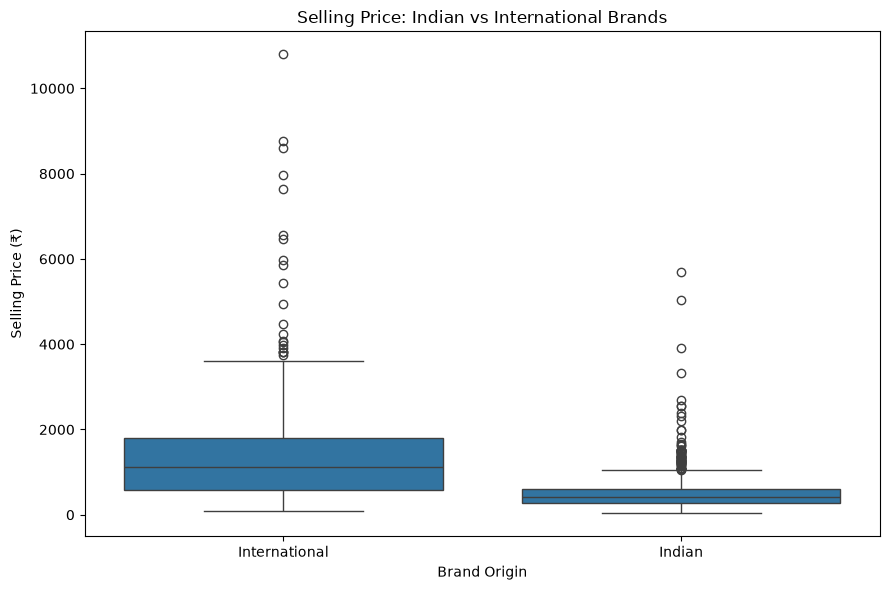

,count,mean,median,std
brand_origin_group,,,,
Indian,1016,505.71,405.5,423.51
International,449,1417.17,1116.0,1269.17


In [12]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df[df["brand_origin_group"].isin(["Indian", "International"])],
    x="brand_origin_group",
    y="selling_price"
)

plt.title("Selling Price: Indian vs International Brands")
plt.xlabel("Brand Origin")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

# Compare descriptive statistics
display(
    df[df["brand_origin_group"].isin(["Indian", "International"])]
    .groupby("brand_origin_group")["selling_price"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

In [13]:
from scipy.stats import mannwhitneyu

indian = df.loc[
    df["brand_origin_group"] == "Indian", "selling_price"
]

international = df.loc[
    df["brand_origin_group"] == "International", "selling_price"
]

# Two-sided Mann–Whitney U test
result = mannwhitneyu(
    indian,
    international,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", result.statistic)
print("P-value:", result.pvalue)

print("Indian median:", indian.median())
print("International median:", international.median())
print("Median price difference:", international.median() - indian.median())

if result.pvalue < 0.05:
    print("Reject H0: evidence of a difference in price distributions.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

Mann–Whitney U statistic: 80478.5
P-value: 5.047613895013329e-87
Indian median: 405.5
International median: 1116.0
Median price difference: 710.5
Reject H0: evidence of a difference in price distributions.


In [14]:
from scipy.stats import mannwhitneyu

indian_discount = df.loc[
    df["brand_origin_group"] == "Indian",
    "discount_pct"
]

international_discount = df.loc[
    df["brand_origin_group"] == "International",
    "discount_pct"
]

print("Indian median discount:", indian_discount.median())
print("International median discount:", international_discount.median())

result = mannwhitneyu(
    indian_discount,
    international_discount,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", result.statistic)
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject H0: evidence of a difference in discount distributions.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

Indian median discount: 14.958775029446409
International median discount: 10.02004008016032
Mann–Whitney U statistic: 274220.5
P-value: 6.366630600348198e-10
Reject H0: evidence of a difference in discount distributions.


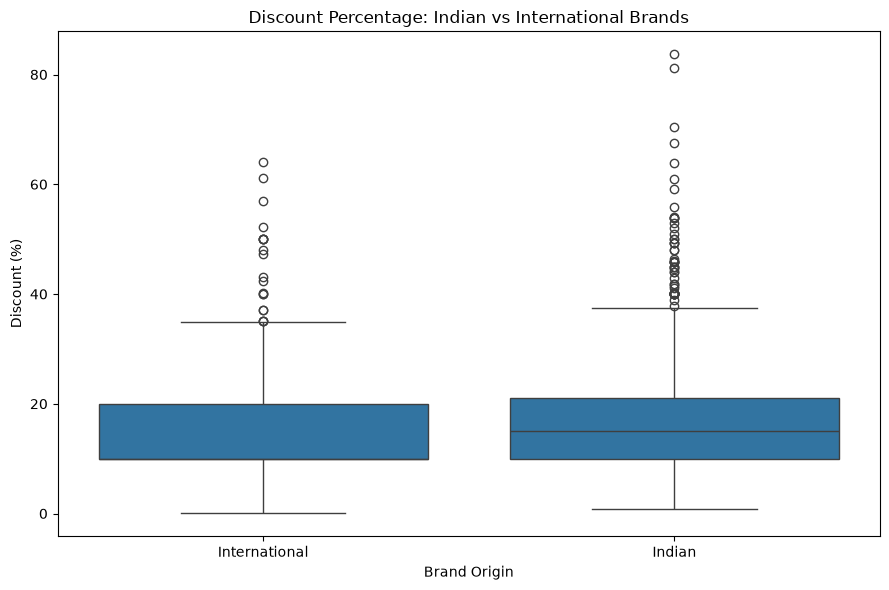

In [15]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df[df["brand_origin_group"].isin(["Indian", "International"])],
    x="brand_origin_group",
    y="discount_pct"
)

plt.title("Discount Percentage: Indian vs International Brands")
plt.xlabel("Brand Origin")
plt.ylabel("Discount (%)")
plt.tight_layout()
plt.show()

,count,mean,median,std
rating,,,,
3.0,2,569.50,569.5,552.25
4.0,1202,703.99,449.0,859.40
5.0,262,1162.05,881.0,939.96


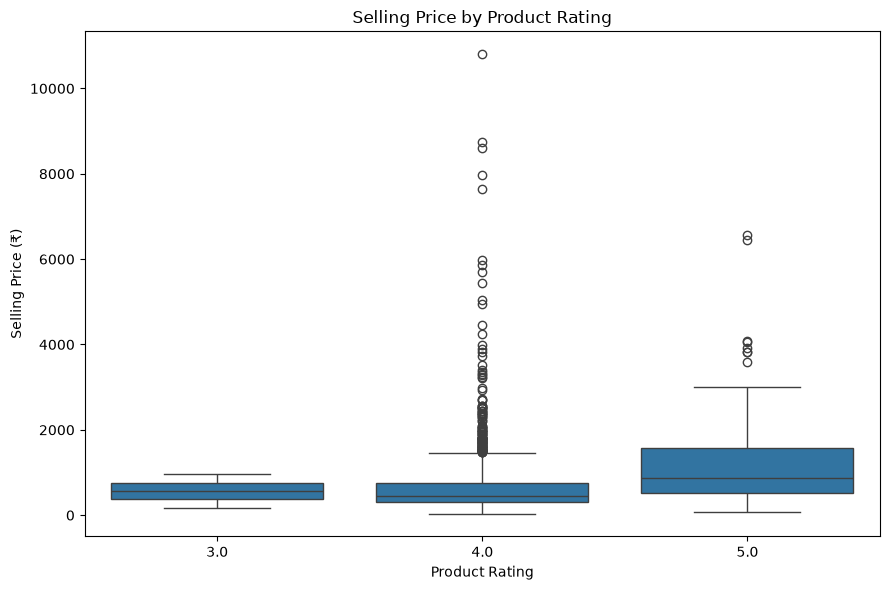

In [16]:
# Summary of selling prices by rating
display(
    df.groupby("rating")["selling_price"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

# Visual comparison
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="rating",
    y="selling_price"
)

plt.title("Selling Price by Product Rating")
plt.xlabel("Product Rating")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

In [17]:
from scipy.stats import mannwhitneyu

price_4 = df.loc[df["rating"] == 4, "selling_price"]
price_5 = df.loc[df["rating"] == 5, "selling_price"]

result = mannwhitneyu(
    price_4,
    price_5,
    alternative="two-sided"
)

print("4-star median:", price_4.median())
print("5-star median:", price_5.median())
print("Median difference:", price_5.median() - price_4.median())
print("Mann–Whitney U statistic:", result.statistic)
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject H0: evidence of a difference in price distributions.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

4-star median: 449.0
5-star median: 881.0
Median difference: 432.0
Mann–Whitney U statistic: 91424.0
P-value: 1.7378337103828218e-26
Reject H0: evidence of a difference in price distributions.


In [18]:
category_summary = (
    df.groupby("category")
    .agg(
        product_count=("product_name", "count"),
        median_price=("selling_price", "median"),
        mean_price=("selling_price", "mean"),
        median_discount=("discount_pct", "median"),
        median_rating=("rating", "median")
    )
    .sort_values("median_price", ascending=False)
    .round(2)
)

display(category_summary)

,product_count,median_price,mean_price,median_discount,median_rating
category,,,,,
Other / Unclear,175,674.0,953.80,16.00,4.0
Serum,173,617.0,1062.11,14.03,4.0
Eye Care,38,572.5,1091.08,15.00,4.0
Sunscreen,223,527.0,800.01,13.03,4.0
Moisturizer,258,523.0,911.23,13.91,4.0
Facial Oil,19,480.0,1087.74,14.97,4.0
Body Care,71,480.0,712.46,20.00,4.0
Toner,63,470.0,863.13,12.00,4.0
Face Mask,84,418.0,596.40,15.03,4.0


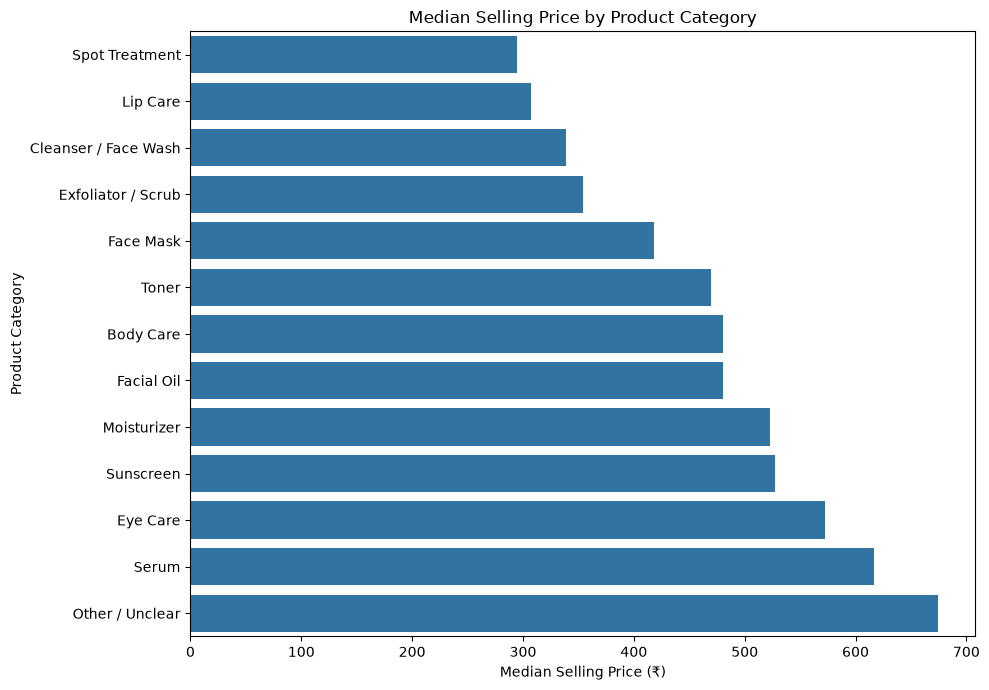

In [19]:
# Median selling price by category
category_summary = category_summary.sort_values("median_price")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=category_summary.reset_index(),
    x="median_price",
    y="category"
)

plt.title("Median Selling Price by Product Category")
plt.xlabel("Median Selling Price (₹)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

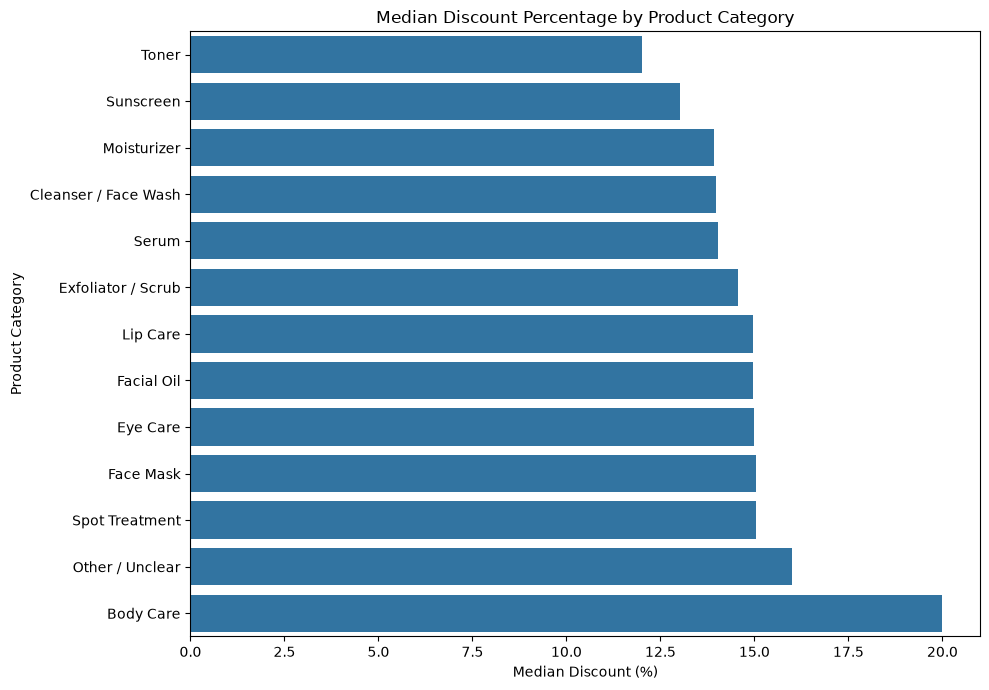

In [20]:
# Median discount by category
discount_summary = (
    df.groupby("category")["discount_pct"]
    .median()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=discount_summary,
    x="discount_pct",
    y="category"
)

plt.title("Median Discount Percentage by Product Category")
plt.xlabel("Median Discount (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [21]:
from scipy.stats import kruskal

# Keep clearly identified categories with at least 20 products
category_counts = df["category"].value_counts()

valid_categories = category_counts[
    (category_counts >= 20) &
    (category_counts.index != "Other / Unclear")
].index

category_data = [
    df.loc[df["category"] == category, "selling_price"].dropna()
    for category in valid_categories
]

# Kruskal-Wallis test
statistic, p_value = kruskal(*category_data)

print("Categories tested:", len(valid_categories))
print("Categories:", list(valid_categories))
print("Kruskal-Wallis H statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: evidence that at least one category's price distribution differs.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

Categories tested: 11
Categories: ['Moisturizer', 'Sunscreen', 'Cleanser / Face Wash', 'Serum', 'Lip Care', 'Face Mask', 'Body Care', 'Toner', 'Exfoliator / Scrub', 'Eye Care', 'Spot Treatment']
Kruskal-Wallis H statistic: 167.34669679387156
P-value: 9.823614109183131e-31
Reject H0: evidence that at least one category's price distribution differs.


In [22]:
%pip install scikit-posthocs

Note: you may need to restart the kernel to use updated packages.


In [42]:
import scikit_posthocs as sp

# Use the same 11 categories as the Kruskal-Wallis test
posthoc_data = df[
    df["category"].isin(valid_categories)
][["category", "selling_price"]].dropna()

dunn_results = sp.posthoc_dunn(
    posthoc_data,
    val_col="selling_price",
    group_col="category",
    p_adjust="bonferroni"
)

display(dunn_results.round(5))

,Body Care,Cleanser / Face Wash,Exfoliator / Scrub,Eye Care,Face Mask,Lip Care,Moisturizer,Serum,Spot Treatment,Sunscreen,Toner
Body Care,1.00000,0.12818,0.17195,1.00000,1.00000,0.01029,1.00000,0.04843,0.09277,1.00000,1.00000
Cleanser / Face Wash,0.12818,1.00000,1.00000,0.00583,1.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.06294
Exfoliator / Scrub,0.17195,1.00000,1.00000,0.00904,1.00000,1.00000,0.00014,0.00000,1.00000,0.00003,0.09257
Eye Care,1.00000,0.00583,0.00904,1.00000,0.08596,0.00051,1.00000,1.00000,0.00647,1.00000,1.00000
Face Mask,1.00000,1.00000,1.00000,0.08596,1.00000,1.00000,0.00112,0.00000,1.00000,0.00025,0.86843
Lip Care,0.01029,1.00000,1.00000,0.00051,1.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00505
Moisturizer,1.00000,0.00000,0.00014,1.00000,0.00112,0.00000,1.00000,0.19577,0.00107,1.00000,1.00000
Serum,0.04843,0.00000,0.00000,1.00000,0.00000,0.00000,0.19577,1.00000,0.00000,1.00000,0.24021
Spot Treatment,0.09277,1.00000,1.00000,0.00647,1.00000,1.00000,0.00107,0.00000,1.00000,0.00042,0.05438
Sunscreen,1.00000,0.00000,0.00003,1.00000,0.00025,0.00000,1.00000,1.00000,0.00042,1.00000,1.00000


In [24]:
from scipy.stats import spearmanr

result = spearmanr(
    df["rating"],
    df["review_count"]
)

print("Spearman correlation:", round(result.statistic, 4))
print("P-value:", result.pvalue)

Spearman correlation: -0.1046
P-value: 5.9749002842545115e-05


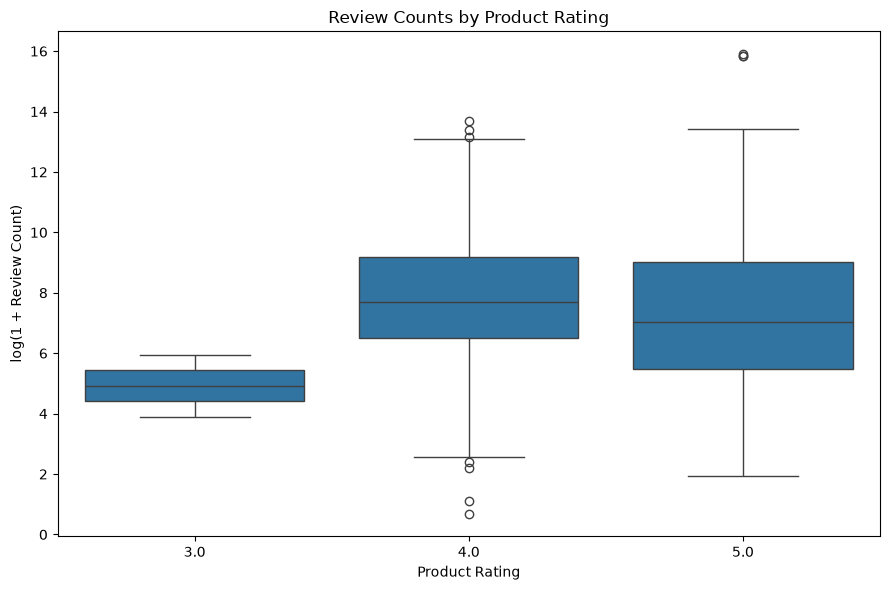

In [25]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="rating",
    y="log_review_count"
)

plt.title("Review Counts by Product Rating")
plt.xlabel("Product Rating")
plt.ylabel("log(1 + Review Count)")
plt.tight_layout()
plt.show()

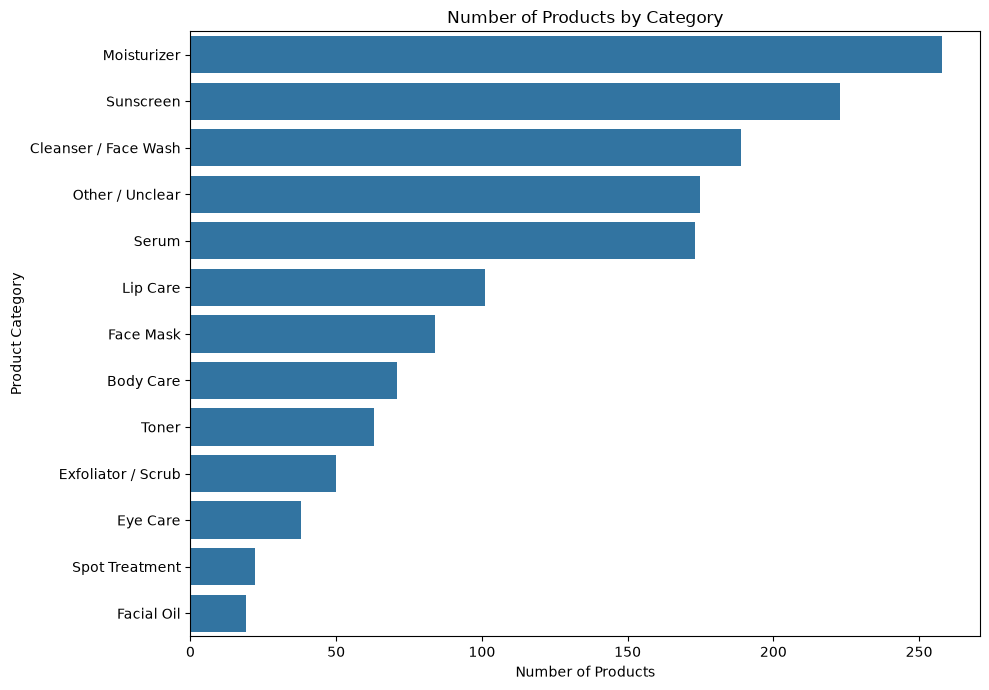

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

category_counts = df["category"].value_counts()

plt.figure(figsize=(10, 7))
sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Number of Products by Category")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

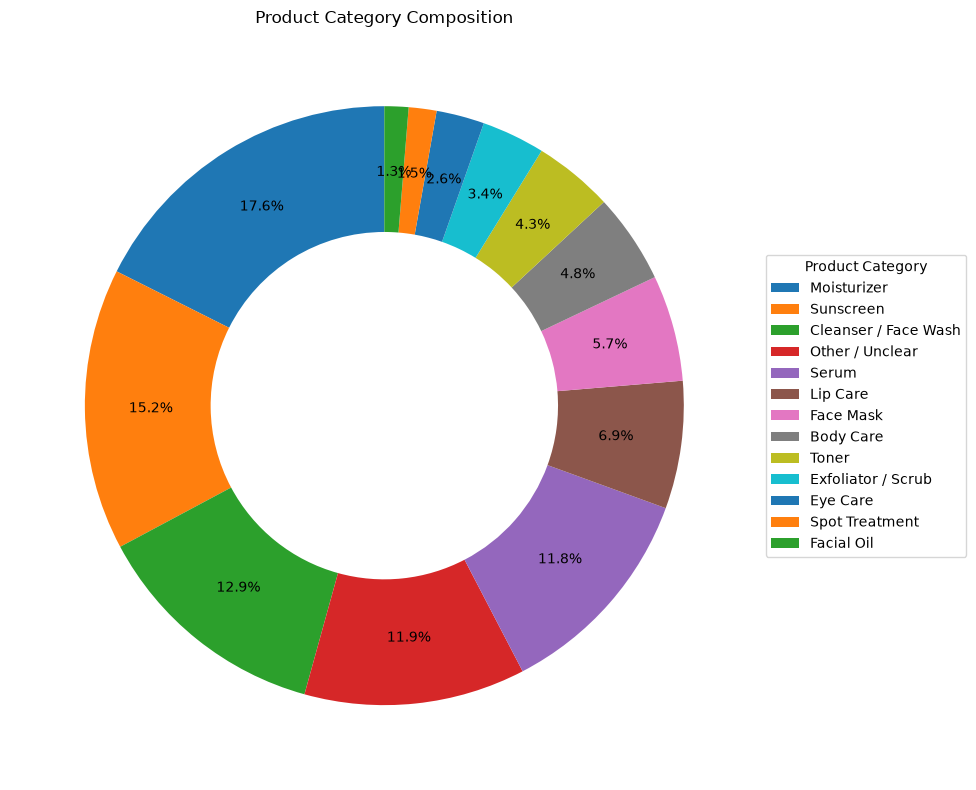

In [27]:
category_counts = df["category"].value_counts()

plt.figure(figsize=(10, 8))

plt.pie(
    category_counts.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.42}
)

plt.legend(
    category_counts.index,
    title="Product Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Product Category Composition")
plt.tight_layout()
plt.show()

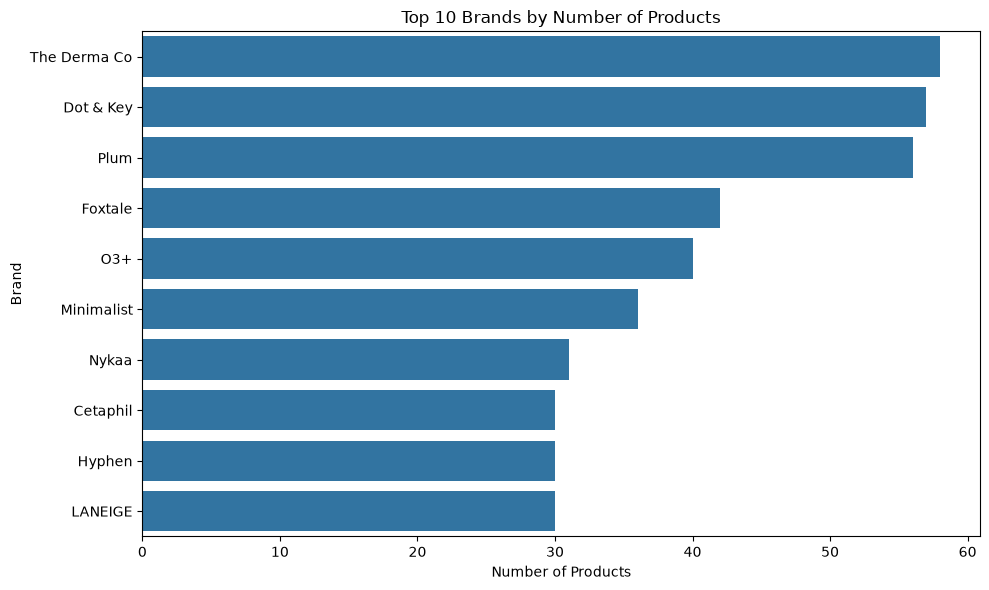

In [28]:
top_brands = df["brand_name"].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_brands.values,
    y=top_brands.index
)

plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

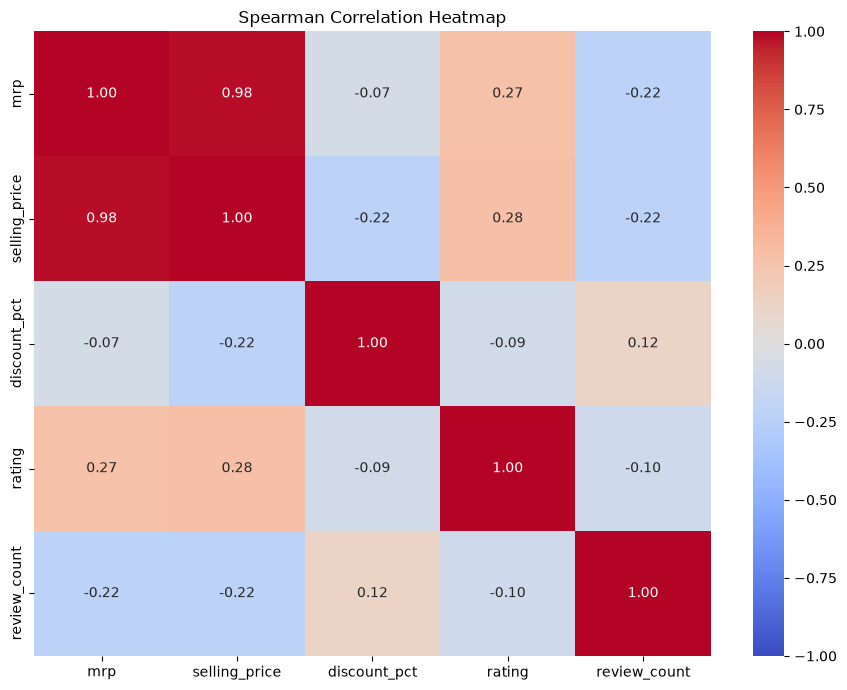

In [29]:
numeric_cols = [
    "mrp",
    "selling_price",
    "discount_pct",
    "rating",
    "review_count"
]

corr = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

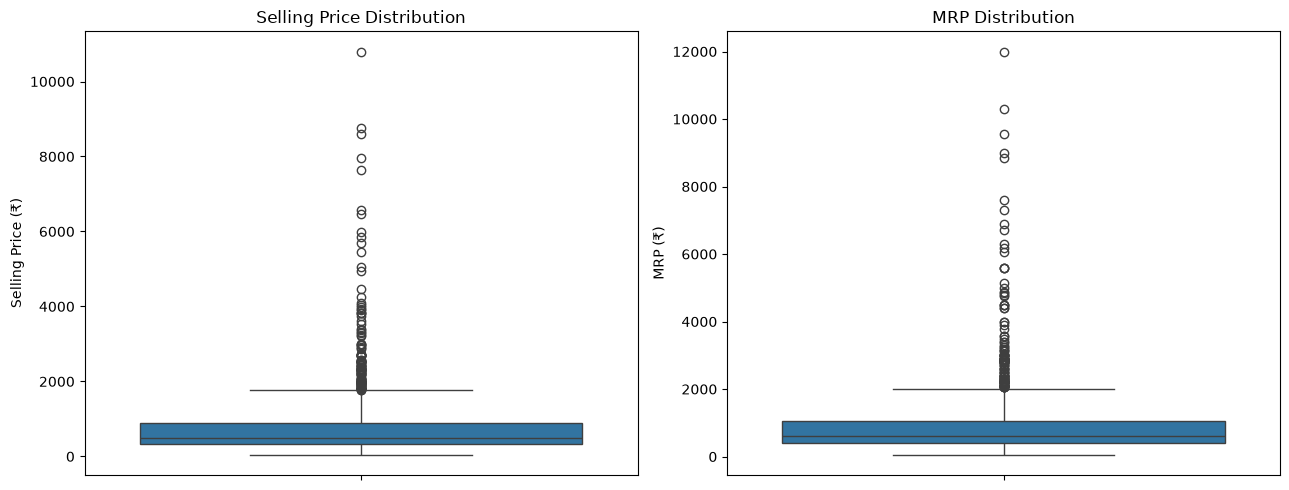

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(y=df["selling_price"], ax=axes[0])
axes[0].set_title("Selling Price Distribution")
axes[0].set_ylabel("Selling Price (₹)")

sns.boxplot(y=df["mrp"], ax=axes[1])
axes[1].set_title("MRP Distribution")
axes[1].set_ylabel("MRP (₹)")

plt.tight_layout()
plt.show()

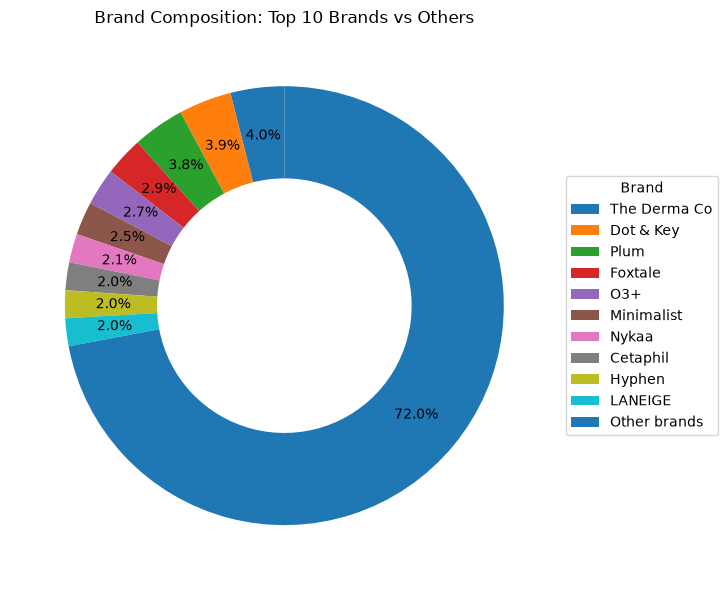

In [44]:
brand_counts = df["brand_name"].value_counts()

top_10 = brand_counts.head(10)
other_count = brand_counts.iloc[10:].sum()

brand_composition = pd.concat([
    top_10,
    pd.Series({"Other brands": other_count})
])

plt.figure(figsize=(10, 6))

plt.pie(
    brand_composition.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.42}
)

plt.legend(
    brand_composition.index,
    title="Brand",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Brand Composition: Top 10 Brands vs Others")
plt.tight_layout()
plt.show()

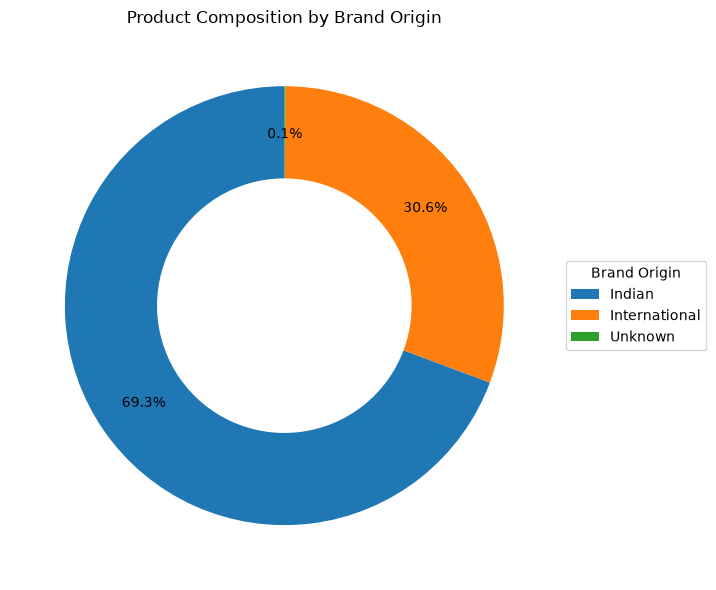

In [45]:
origin_counts = df["brand_origin_group"].value_counts()

plt.figure(figsize=(8, 6))

plt.pie(
    origin_counts.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.42}
)

plt.legend(
    origin_counts.index,
    title="Brand Origin",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Product Composition by Brand Origin")
plt.tight_layout()
plt.show()

In [33]:
# Identify unusually large review counts
review_threshold = 1_000_000

extreme_reviews = df.loc[
    df["review_count"] > review_threshold,
    ["product_name", "brand_name", "category", "review_count"]
].copy()

print("Total products:", len(df))
print("Products above 1 million reviews:", len(extreme_reviews))

display(extreme_reviews.to_string(index=False))

Total products: 1466
Products above 1 million reviews: 3


'                                                   product_name brand_name  category  review_count\nNykaa Green Tea + Aloe Vera Sheet Mask For Hydrated Skin - F...      Nykaa Face Mask     7619790.0\nNykaa Gold Sheet Mask For Revitalized & Youthful Skin-Formul...      Nykaa Face Mask     7619790.0\nNykaa Naturals Skin Secrets Bestseller Sheet Mask - Monthly ...      Nykaa Face Mask     7997482.0'

In [34]:
df["extreme_review_flag"] = (
    df["review_count"] > 1_000_000
)

print(df["extreme_review_flag"].value_counts())

extreme_review_flag
False    1463
True        3
Name: count, dtype: int64


In [35]:
from scipy.stats import mannwhitneyu

indian = df.loc[
    df["brand_origin_group"] == "Indian",
    "selling_price"
].dropna()

international = df.loc[
    df["brand_origin_group"] == "International",
    "selling_price"
].dropna()

# Put international prices first so a positive effect
# indicates that international prices tend to be higher.
result = mannwhitneyu(
    international,
    indian,
    alternative="two-sided"
)

n_int = len(international)
n_ind = len(indian)

# Cliff's delta: probability of international > Indian
# minus probability of Indian > international.
cliffs_delta = 2 * result.statistic / (n_int * n_ind) - 1

print("International products:", n_int)
print("Indian products:", n_ind)
print("Cliff's delta:", round(cliffs_delta, 4))

International products: 449
Indian products: 1016
Cliff's delta: 0.6472


In [36]:
indian_discount = df.loc[
    df["brand_origin_group"] == "Indian",
    "discount_pct"
].dropna()

international_discount = df.loc[
    df["brand_origin_group"] == "International",
    "discount_pct"
].dropna()

result_discount = mannwhitneyu(
    international_discount,
    indian_discount,
    alternative="two-sided"
)

delta_discount = (
    2 * result_discount.statistic
    / (len(international_discount) * len(indian_discount))
    - 1
)

print("Indian median discount:", indian_discount.median())
print("International median discount:", international_discount.median())
print("Cliff's delta:", round(delta_discount, 4))

Indian median discount: 14.958775029446409
International median discount: 10.02004008016032
Cliff's delta: -0.2022


In [37]:
from scipy.stats import kruskal

# Exclude "Other / Unclear" and categories with fewer than 20 products
category_counts = df["category"].value_counts()

eligible_categories = category_counts[
    (category_counts >= 20) &
    (category_counts.index != "Other / Unclear")
].index

category_data = [
    df.loc[df["category"] == category, "selling_price"].dropna()
    for category in eligible_categories
]

# Number of valid observations and groups
N = sum(len(group) for group in category_data)
k = len(category_data)

# Kruskal-Wallis test
H, p = kruskal(*category_data)

# Epsilon-squared effect size
epsilon_squared = (H - k + 1) / (N - k)

print("Number of observations:", N)
print("Number of categories:", k)
print("Kruskal-Wallis H:", H)
print("P-value:", p)
print("Epsilon-squared:", round(epsilon_squared, 4))

Number of observations: 1272
Number of categories: 11
Kruskal-Wallis H: 167.34669679387156
P-value: 9.823614109183131e-31
Epsilon-squared: 0.1248


In [38]:
from scipy.stats import spearmanr

# Original correlation: all products with valid values
data = df[["rating", "review_count"]].dropna()

rho_original, p_original = spearmanr(
    data["rating"],
    data["review_count"]
)

# Identify the three extreme review counts
extreme_threshold = 1_000_000

data_without_extremes = data[
    data["review_count"] < extreme_threshold
]

rho_clean, p_clean = spearmanr(
    data_without_extremes["rating"],
    data_without_extremes["review_count"]
)

print("BEFORE excluding extreme review counts")
print("Products:", len(data))
print("Spearman correlation:", round(rho_original, 4))
print("P-value:", p_original)

print("\nAFTER excluding extreme review counts")
print("Products:", len(data_without_extremes))
print("Spearman correlation:", round(rho_clean, 4))
print("P-value:", p_clean)

BEFORE excluding extreme review counts
Products: 1466
Spearman correlation: -0.1046
P-value: 5.9749002842545115e-05

AFTER excluding extreme review counts
Products: 1463
Spearman correlation: -0.1131
P-value: 1.4565257630076647e-05


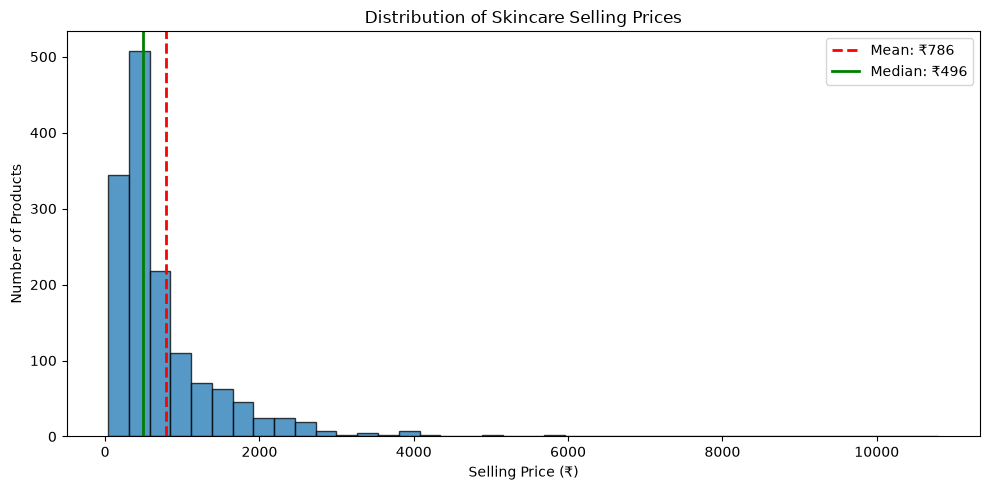

In [39]:
import matplotlib.pyplot as plt

prices = df["selling_price"].dropna()
mean_price = prices.mean()
median_price = prices.median()

plt.figure(figsize=(10, 5))
plt.hist(prices, bins=40, edgecolor="black", alpha=0.75)

# Added color="red" for the Mean line
plt.axvline(
    mean_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: ₹{mean_price:,.0f}",
)

# Added color="green" for the Median line
plt.axvline(
    median_price,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Median: ₹{median_price:,.0f}",
)

plt.title("Distribution of Skincare Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Products")
plt.legend()
plt.tight_layout()
plt.show()


In [40]:
print(f"Mean selling price: ₹{df['selling_price'].mean():,.2f}")
print(f"Median selling price: ₹{df['selling_price'].median():,.2f}")

Mean selling price: ₹785.67
Median selling price: ₹496.50


C:\Users\Mukundraj\AppData\Local\Temp\ipykernel_1104\2647794310.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


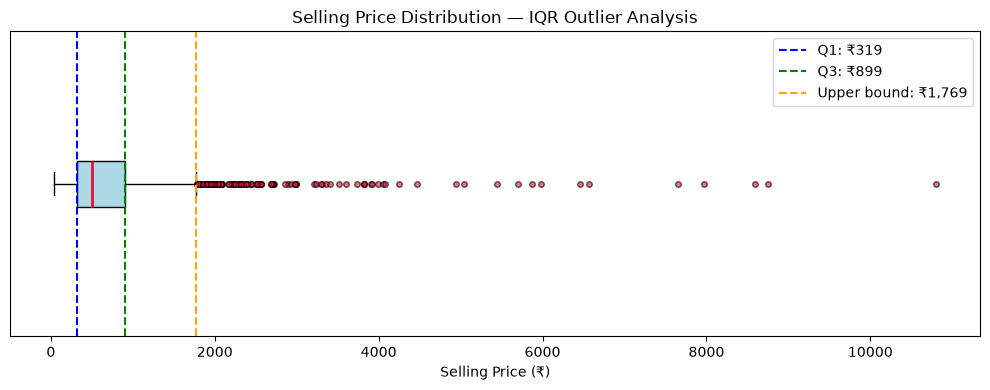

Q1: ₹319.00
Median: ₹496.50
Q3: ₹899.00
IQR: ₹580.00
Upper bound: ₹1,769.00
Potential outliers: 131 (8.94%)


In [41]:
import matplotlib.pyplot as plt

prices = df["selling_price"].dropna()

q1 = prices.quantile(0.25)
q3 = prices.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = prices[(prices < lower_bound) | (prices > upper_bound)]

plt.figure(figsize=(10, 4))

plt.boxplot(
    prices,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="crimson", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="crimson",
        markersize=4,
        alpha=0.6
    )
)

plt.axvline(q1, color="blue", linestyle="--", label=f"Q1: ₹{q1:.0f}")
plt.axvline(q3, color="green", linestyle="--", label=f"Q3: ₹{q3:.0f}")
plt.axvline(
    upper_bound,
    color="orange",
    linestyle="--",
    label=f"Upper bound: ₹{upper_bound:,.0f}"
)

plt.title("Selling Price Distribution — IQR Outlier Analysis")
plt.xlabel("Selling Price (₹)")
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

print(f"Q1: ₹{q1:,.2f}")
print(f"Median: ₹{prices.median():,.2f}")
print(f"Q3: ₹{q3:,.2f}")
print(f"IQR: ₹{iqr:,.2f}")
print(f"Upper bound: ₹{upper_bound:,.2f}")
print(f"Potential outliers: {len(outliers)} ({len(outliers)/len(prices)*100:.2f}%)")